# Étape 5 : Classification par machine learning
Objectif : comparer quatre algorithmes (KNN, SVM, Random Forest, XGBoost) sur les différentes représentations de couleur (expériences E1 à E7), avec les caractéristiques de couleur seules, de texture seules, puis combinées.

**Protocole :** validation croisée sur les 5 plis de l'étape 2 (stratifiés et regroupés par fève) ; standardisation intégrée au pipeline ; hyperparamètres réglés par recherche en grille ; métrique principale : **F1 macro**. L'ensemble de test n'est utilisé qu'à la fin, pour les meilleurs modèles.

In [1]:
#Chargement 

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

GRAINE = 42
df = pd.read_csv("../results/tables/02_decoupage.csv")
y = df["label"].values

F = {nom: pd.read_csv(f"../results/features/caracteristiques_{nom}.csv.gz").drop(columns=["fichier", "classe"])
     for nom in ["couleur", "glcm", "lbp", "gabor", "hog"]}

# Entraînement et plis de validation croisée (étape 2)
idx_train = np.where(df["partition"] == "train")[0]
idx_test = np.where(df["partition"] == "test")[0]
y_tr = y[idx_train]
pli_tr = df["pli"].values[idx_train]
plis = [(np.where(pli_tr != k)[0], np.where(pli_tr == k)[0]) for k in range(5)]
print("Entraînement :", len(idx_train), "| Test :", len(idx_test), "| Plis :", [len(v) for _, v in plis])

Entraînement : 3576 | Test : 894 | Plis : [715, 715, 715, 716, 715]


In [2]:
#Les ensembles de caractéristiques

def couleur(*espaces):
    """Caractéristiques de couleur des espaces demandés (ex. couleur("RGB", "LAB"))."""
    colonnes = [c for c in F["couleur"].columns if c.split("_")[0] in espaces]
    return F["couleur"][colonnes]

texture = pd.concat([F["glcm"], F["lbp"], F["gabor"]], axis=1)

EXPERIENCES = {"E1": ("RGB",), "E2": ("HSV",), "E3": ("LAB",),
               "E5": ("RGB", "HSV"), "E6": ("RGB", "LAB"), "E7": ("RGB", "HSV", "LAB")}

ensembles = {}
for code, espaces in EXPERIENCES.items():
    nom = " + ".join(espaces)
    ensembles[(code, nom, "Couleur seule")] = couleur(*espaces)
    ensembles[(code, nom, "Couleur + texture")] = pd.concat([couleur(*espaces), texture], axis=1)
ensembles[("T", "—", "Texture seule")] = texture

for (code, nom, type_c), M in ensembles.items():
    print(f"{code:3s} {nom:17s} {type_c:18s} : {M.shape[1]} caractéristiques")

E1  RGB               Couleur seule      : 45 caractéristiques
E1  RGB               Couleur + texture  : 87 caractéristiques
E2  HSV               Couleur seule      : 45 caractéristiques
E2  HSV               Couleur + texture  : 87 caractéristiques
E3  LAB               Couleur seule      : 45 caractéristiques
E3  LAB               Couleur + texture  : 87 caractéristiques
E5  RGB + HSV         Couleur seule      : 90 caractéristiques
E5  RGB + HSV         Couleur + texture  : 132 caractéristiques
E6  RGB + LAB         Couleur seule      : 90 caractéristiques
E6  RGB + LAB         Couleur + texture  : 132 caractéristiques
E7  RGB + HSV + LAB   Couleur seule      : 135 caractéristiques
E7  RGB + HSV + LAB   Couleur + texture  : 177 caractéristiques
T   —                 Texture seule      : 42 caractéristiques


In [3]:
#les modèles et leurs grilles d’hyperparamètres

MODELES = {
    "KNN": (make_pipeline(StandardScaler(), KNeighborsClassifier()),
            {"kneighborsclassifier__n_neighbors": [5, 11, 21],
             "kneighborsclassifier__weights": ["uniform", "distance"]}),
    "SVM": (make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced")),
            {"svc__C": [1, 10, 100, 1000],
             "svc__gamma": ["scale", 0.01]}),
    "Random Forest": (make_pipeline(StandardScaler(), RandomForestClassifier(
                          n_estimators=300, class_weight="balanced", random_state=GRAINE)),
            {"randomforestclassifier__max_features": ["sqrt", 0.3],
             "randomforestclassifier__min_samples_leaf": [1, 3]}),
    "XGBoost": (make_pipeline(StandardScaler(), XGBClassifier(
                          n_estimators=300, learning_rate=0.1, tree_method="hist",
                          random_state=GRAINE, n_jobs=1)),
            {"xgbclassifier__max_depth": [3, 6],
             "xgbclassifier__subsample": [0.8, 1.0]}),
}

In [ ]:
#La boucle des expériences

resultats = []
debut = time.time()

for (code, nom, type_c), M in ensembles.items():
    X_tr = M.values[idx_train]
    for algo, (pipeline, grille) in MODELES.items():
        recherche = GridSearchCV(pipeline, grille, cv=plis, scoring="f1_macro", n_jobs=-1)
        recherche.fit(X_tr, y_tr)
        i = recherche.best_index_
        resultats.append({
            "Expérience": code, "Représentation": nom, "Caractéristiques": type_c, "Algorithme": algo,
            "Nb caractéristiques": M.shape[1],
            "F1 macro (moyenne)": recherche.best_score_,
            "F1 macro (écart-type)": recherche.cv_results_["std_test_score"][i],
            "Temps d'entraînement (s)": recherche.cv_results_["mean_fit_time"][i],
            "Meilleurs paramètres": recherche.best_params_,
        })
    print(f"{code} – {type_c} terminé ({time.time() - debut:.0f} s écoulées)")

df_res = pd.DataFrame(resultats)
df_res.to_csv("../results/tables/05_resultats_validation_croisee.csv", index=False)

E1 – Couleur seule terminé (17 s écoulées)
E1 – Couleur + texture terminé (40 s écoulées)
E2 – Couleur seule terminé (53 s écoulées)
E2 – Couleur + texture terminé (76 s écoulées)
E3 – Couleur seule terminé (86 s écoulées)
E3 – Couleur + texture terminé (108 s écoulées)
E5 – Couleur seule terminé (130 s écoulées)


In [ ]:
#le tableau comparatif. On présente chaque score sous la forme moyenne ± écart-type

df_res["F1 macro (%)"] = (df_res["F1 macro (moyenne)"] * 100).round(1).astype(str) + " ± " + \
                         (df_res["F1 macro (écart-type)"] * 100).round(1).astype(str)

tableau = df_res.pivot_table(index=["Expérience", "Représentation", "Caractéristiques"],
                             columns="Algorithme", values="F1 macro (%)", aggfunc="first")
tableau = tableau[["KNN", "SVM", "Random Forest", "XGBoost"]]
tableau.to_csv("../results/tables/05_tableau_comparatif.csv")
tableau

Algorithme                                           KNN         SVM  \
Expérience Représentation  Caractéristiques                            
E1         RGB             Couleur + texture  93.2 ± 1.5  96.7 ± 0.5   
                           Couleur seule      92.0 ± 0.9  93.8 ± 1.3   
E2         HSV             Couleur + texture  94.6 ± 1.3  96.9 ± 0.6   
                           Couleur seule      93.8 ± 1.2  93.2 ± 0.8   
E3         LAB             Couleur + texture  94.3 ± 0.8  97.3 ± 0.6   
                           Couleur seule      93.4 ± 0.7  93.7 ± 0.7   
E5         RGB + HSV       Couleur + texture  94.7 ± 1.1  97.3 ± 0.7   
                           Couleur seule      94.1 ± 1.3  94.9 ± 1.2   
E6         RGB + LAB       Couleur + texture  94.4 ± 1.4  97.3 ± 0.4   
                           Couleur seule      93.8 ± 0.9  95.2 ± 1.0   
E7         RGB + HSV + LAB Couleur + texture  95.1 ± 1.3  97.6 ± 0.5   
                           Couleur seule      94.7 ± 1.0  96.1 ± 0.8   
T          —               Texture seule      89.5 ± 1.6  93.7 ± 0.7   

Algorithme                                   Random Forest     XGBoost  
Expérience Représentation  Caractéristiques                             
E1         RGB             Couleur + texture    93.3 ± 0.9  95.8 ± 0.2  
                           Couleur seule        92.2 ± 1.2  93.6 ± 1.2  
E2         HSV             Couleur + texture    94.1 ± 0.7  96.0 ± 0.6  
                           Couleur seule        93.2 ± 1.0  94.2 ± 0.8  
E3         LAB             Couleur + texture    93.9 ± 1.0  95.7 ± 0.8  
                           Couleur seule        93.1 ± 0.8  94.3 ± 0.9  
E5         RGB + HSV       Couleur + texture    94.3 ± 0.8  96.2 ± 0.5  
                           Couleur seule        93.6 ± 1.2  95.0 ± 0.9  
E6         RGB + LAB       Couleur + texture    94.2 ± 0.9  96.2 ± 0.5  
                           Couleur seule        93.6 ± 1.0  94.8 ± 0.7  
E7         RGB + HSV + LAB Couleur + texture    94.5 ± 0.9  96.4 ± 0.5  
                           Couleur seule        94.0 ± 1.0  95.2 ± 0.8  
T          —               Texture seule        90.1 ± 0.8  91.9 ± 1.1

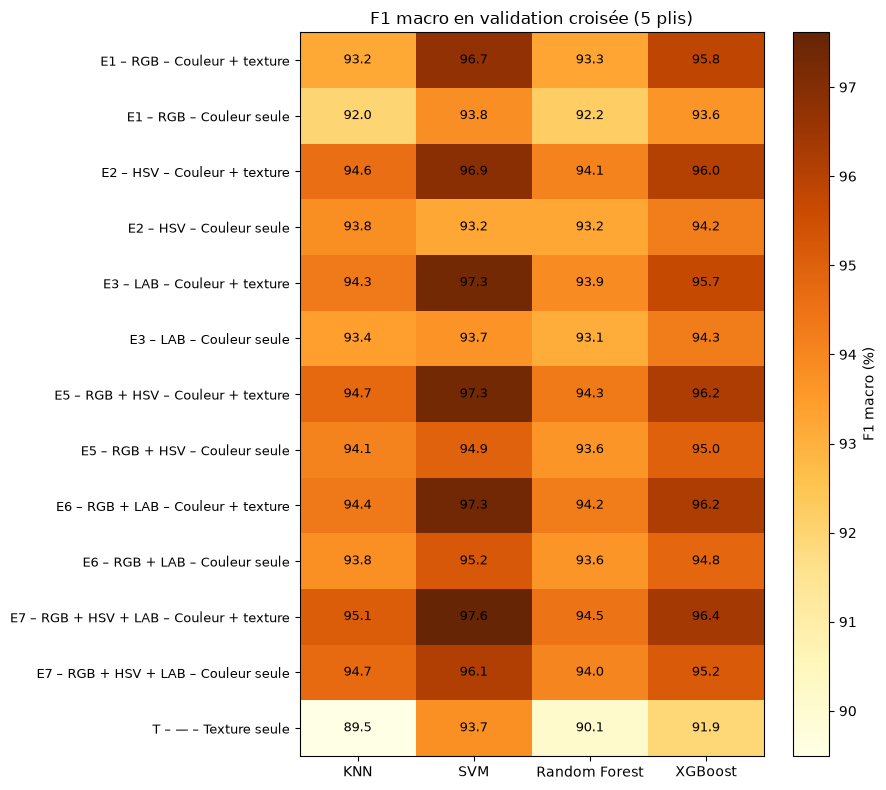

In [ ]:
#carte de chaleur.

carte = df_res.pivot_table(index=["Expérience", "Représentation", "Caractéristiques"],
                           columns="Algorithme", values="F1 macro (moyenne)")[["KNN", "SVM", "Random Forest", "XGBoost"]] * 100

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(carte.values, cmap="YlOrBr", aspect="auto")
ax.set_xticks(range(carte.shape[1]), carte.columns)
ax.set_yticks(range(carte.shape[0]), [f"{e} – {r} – {c}" for e, r, c in carte.index], fontsize=9)
for i in range(carte.shape[0]):
    for j in range(carte.shape[1]):
        ax.text(j, i, f"{carte.values[i, j]:.1f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, label="F1 macro (%)")
plt.title("F1 macro en validation croisée (5 plis)")
plt.tight_layout()
plt.savefig("../results/figures/05_carte_resultats.png", dpi=150)
plt.show()

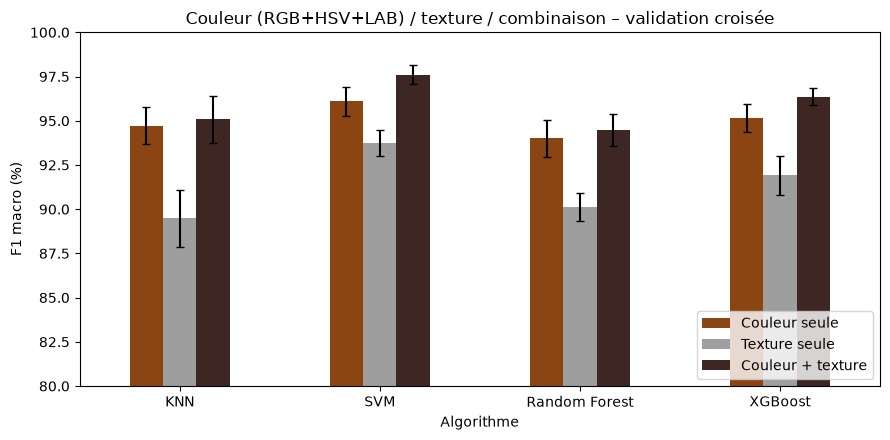

In [ ]:
#couleur seule, texture seule ou les deux ?

selection = df_res[(df_res["Expérience"].isin(["E7", "T"]))]
comparaison = selection.pivot_table(index="Algorithme", columns="Caractéristiques",
                                    values="F1 macro (moyenne)")[["Couleur seule", "Texture seule", "Couleur + texture"]] * 100
ecarts = selection.pivot_table(index="Algorithme", columns="Caractéristiques",
                               values="F1 macro (écart-type)")[comparaison.columns] * 100

ax = comparaison.loc[["KNN", "SVM", "Random Forest", "XGBoost"]].plot(
    kind="bar", yerr=ecarts.loc[["KNN", "SVM", "Random Forest", "XGBoost"]], capsize=3,
    figsize=(9, 4.5), color=["#8B4513", "#9E9E9E", "#3E2723"], rot=0)
ax.set_ylim(80, 100)
ax.set_ylabel("F1 macro (%)")
ax.set_title("Couleur (RGB+HSV+LAB) / texture / combinaison – validation croisée")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../results/figures/05_couleur_texture_combinaison.png", dpi=150)
plt.show()

**Analyse des résultats en validation croisée (F1 macro) :**
- **Meilleure combinaison : SVM + E7 (RGB + HSV + LAB) + couleur et texture, 97,6 ± 0,5 %.** Le SVM est le meilleur algorithme pour toutes les représentations, devant XGBoost ; KNN et Random Forest sont en retrait.
- **Espaces de couleur pris seuls :** RGB, HSV et LAB obtiennent des scores très proches (≈ 93-94 % avec le SVM), avec des écarts inférieurs aux écarts-types. Contrairement à l'analyse canal par canal de l'étape 3, un classifieur qui combine les 45 caractéristiques d'un espace parvient à extraire l'information chromatique même en RGB.
- **Fusion des espaces :** combiner les espaces améliore les résultats pour tous les algorithmes (SVM couleur seule : 93,8 % en RGB → 96,1 % en RGB + HSV + LAB).
- **Texture :** seule, elle atteint 93,7 % avec le SVM, autant qu'un espace de couleur seul. Ajoutée à la couleur, elle apporte environ 3 points pour chaque représentation : **couleur et texture sont complémentaires**.
- **Compromis :** E3 (LAB + texture, 87 caractéristiques) obtient 97,3 %, un score statistiquement équivalent à E7 avec deux fois moins de caractéristiques.
- **Stabilité :** les écarts-types restent faibles (≤ 1,6 %), signe de résultats stables d'un pli à l'autre.
- **Le gain de la texture dépend de l'algorithme** : il est net pour le SVM (96,1 → 97,6 %) et XGBoost (95,2 → 96,4 %), dont les intervalles ne se chevauchent pas, mais faible et non significatif pour le KNN (94,7 → 95,1 %) et le Random Forest (94,0 → 94,5 %). Pour le KNN, l'ajout de caractéristiques dilue les distances entre fèves (malédiction de la dimension), ce qui limite le bénéfice d'informations supplémentaires.

In [ ]:
#Réentraînement et évaluation sur le test

from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, cohen_kappa_score, roc_auc_score, confusion_matrix)

M_best = ensembles[("E7", "RGB + HSV + LAB", "Couleur + texture")]
X_tr, X_te = M_best.values[idx_train], M_best.values[idx_test]
y_te = y[idx_test]
classes = ["category 1", "category 2", "category 3"]

lignes_test, modeles_finaux = [], {}
for algo, (pipeline, _) in MODELES.items():
    params = df_res[(df_res["Expérience"] == "E7") & (df_res["Caractéristiques"] == "Couleur + texture")
                    & (df_res["Algorithme"] == algo)]["Meilleurs paramètres"].iloc[0]
    modele = clone(pipeline).set_params(**params)
    if algo == "SVM":
        modele.set_params(svc__probability=True)      # nécessaire pour calculer la ROC-AUC
    modele.fit(X_tr, y_tr)
    pred = modele.predict(X_te)
    proba = modele.predict_proba(X_te)
    modeles_finaux[algo] = (modele, pred, proba)
    lignes_test.append({
        "Algorithme": algo,
        "Accuracy": accuracy_score(y_te, pred),
        "Precision (macro)": precision_score(y_te, pred, average="macro"),
        "Recall (macro)": recall_score(y_te, pred, average="macro"),
        "F1 (macro)": f1_score(y_te, pred, average="macro"),
        "MCC": matthews_corrcoef(y_te, pred),
        "Kappa de Cohen": cohen_kappa_score(y_te, pred),
        "ROC-AUC (macro, OvR)": roc_auc_score(y_te, proba, multi_class="ovr", average="macro"),
    })

df_test = pd.DataFrame(lignes_test).set_index("Algorithme")
df_test.to_csv("../results/tables/05_resultats_test.csv")
(df_test * 100).round(1)


/opt/anaconda3/envs/projet2-feves/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision (macro),Recall (macro),F1 (macro),MCC,Kappa de Cohen,"ROC-AUC (macro, OvR)"
Algorithme,,,,,,,
KNN,94.2,95.3,94.8,95.0,90.9,90.9,98.7
SVM,97.8,98.1,98.1,98.1,96.5,96.5,99.6
Random Forest,94.4,95.3,95.1,95.2,91.2,91.2,99.4
XGBoost,97.0,97.5,97.4,97.5,95.3,95.3,99.7


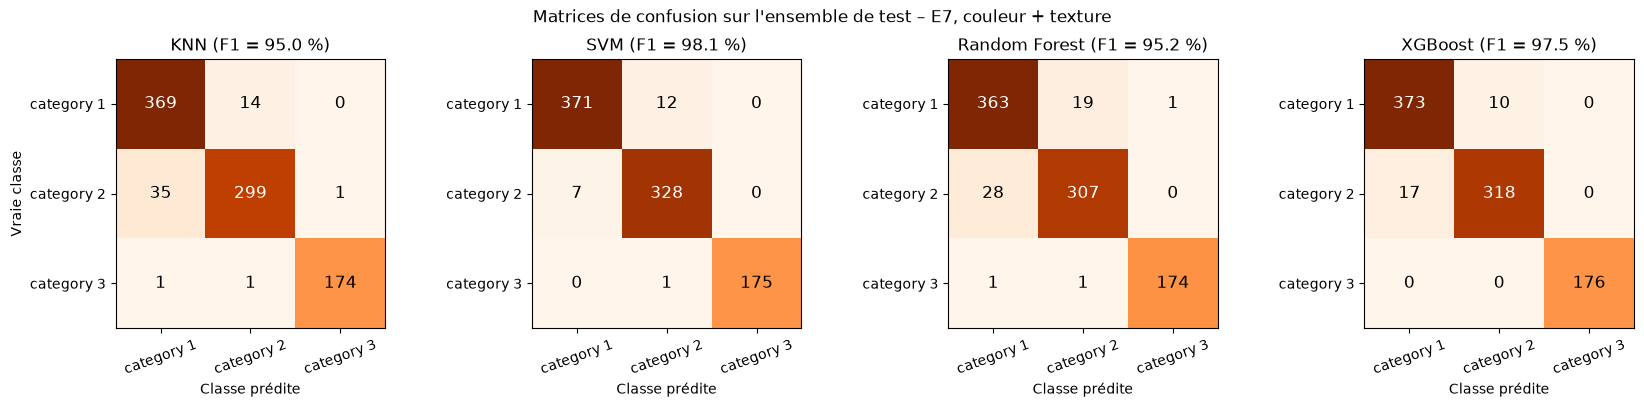

In [ ]:
#matrices de confusion sur le test

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (algo, (_, pred, _)) in zip(axes, modeles_finaux.items()):
    mc = confusion_matrix(y_te, pred)
    ax.imshow(mc, cmap="Oranges")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, mc[i, j], ha="center", va="center", fontsize=12,
                    color="white" if mc[i, j] > mc.max() / 2 else "black")
    ax.set_xticks(range(3), classes, rotation=20)
    ax.set_yticks(range(3), classes)
    ax.set_xlabel("Classe prédite")
    ax.set_title(f"{algo} (F1 = {df_test.loc[algo, 'F1 (macro)'] * 100:.1f} %)")
axes[0].set_ylabel("Vraie classe")
plt.suptitle("Matrices de confusion sur l'ensemble de test – E7, couleur + texture")
plt.tight_layout()
plt.savefig("../results/figures/05_matrices_confusion_test.png", dpi=150)
plt.show()

**Évaluation sur l'ensemble de test (E7, couleur + texture) :**
- Le **SVM** reste le meilleur modèle : **F1 macro 98,1 %**, accuracy 97,8 %, MCC 0,965, ROC-AUC 99,6 %. Les scores de test sont cohérents avec la validation croisée (97,6 ± 0,5 %), ce qui confirme une bonne généralisation.
- **19 des 20 erreurs du SVM sont des confusions entre les Categories 1 et 2**, comme prévu dès l'exploration. La Category 3 est reconnue presque parfaitement par les quatre modèles (174 à 176 sur 176).
- Les erreurs sont **asymétriques** pour KNN, Random Forest et XGBoost : les fèves de la Category 2 sont plus souvent classées en Category 1 que l'inverse (35 contre 14 pour le KNN). Le SVM est le plus équilibré (12 contre 7).
- La ROC-AUC dépasse 98,7 % pour tous les modèles : les erreurs concernent des fèves situées à la frontière entre deux classes.

In [ ]:
#séparation au hasard ou par fève ?

from sklearn.model_selection import StratifiedKFold, cross_val_score

X_tr = M_best.values[idx_train]
comparaison_fuite = []

for algo in ["SVM", "KNN"]:
    modele = modeles_finaux[algo][0]
    if algo == "SVM":
        modele = clone(modele).set_params(svc__probability=False)   # plus rapide, inutile ici

    # Plis au hasard : répétés avec 5 graines pour une moyenne fiable
    scores_hasard = [cross_val_score(modele, X_tr, y_tr, scoring="f1_macro",
                                     cv=StratifiedKFold(5, shuffle=True, random_state=g)).mean()
                     for g in range(5)]
    # Nos plis : chaque fève dans un seul pli
    scores_groupes = cross_val_score(modele, X_tr, y_tr, cv=plis, scoring="f1_macro")

    comparaison_fuite.append({
        "Algorithme": algo,
        "Plis au hasard (avec fuite)": np.mean(scores_hasard) * 100,
        "Plis par fève (sans fuite)": scores_groupes.mean() * 100,
    })

df_fuite = pd.DataFrame(comparaison_fuite).set_index("Algorithme")
df_fuite["Surestimation (points)"] = df_fuite["Plis au hasard (avec fuite)"] - df_fuite["Plis par fève (sans fuite)"]
df_fuite.round(2)

/opt/anaconda3/envs/projet2-feves/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/anaconda3/envs/projet2-feves/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/anaconda3/envs/projet2-feves/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/anaconda3/envs/projet2-feves/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probab

,Plis au hasard (avec fuite),Plis par fève (sans fuite),Surestimation (points)
Algorithme,,,
SVM,98.05,97.61,0.44
KNN,95.90,95.08,0.82


In [ ]:
#HOG apporte-t-il quelque chose ? C’est la vérification de l’hypothèse de l’étape 4.


params_svm = df_res[(df_res["Expérience"] == "E7") & (df_res["Caractéristiques"] == "Couleur + texture")
                    & (df_res["Algorithme"] == "SVM")]["Meilleurs paramètres"].iloc[0]
svm = clone(MODELES["SVM"][0]).set_params(**params_svm)

tests_hog = {
    "E7 couleur + texture (sans HOG)": M_best,
    "E7 couleur + texture + HOG": pd.concat([M_best, F["hog"]], axis=1),
    "HOG seul": F["hog"],
}
lignes_hog = []
for nom, M in tests_hog.items():
    s = cross_val_score(svm, M.values[idx_train], y_tr, cv=plis, scoring="f1_macro")
    lignes_hog.append({"Ensemble": nom, "Nb caractéristiques": M.shape[1],
                       "F1 macro (%)": f"{s.mean() * 100:.1f} ± {s.std() * 100:.1f}"})
pd.DataFrame(lignes_hog)

,Ensemble,Nb caractéristiques,F1 macro (%)
0,E7 couleur + texture (sans HOG),177,97.6 ± 0.5
1,E7 couleur + texture + HOG,501,96.8 ± 0.9
2,HOG seul,324,90.6 ± 0.7
